# Telco Customer Churn - 04. Model Evaluation
Steps 14-15: evaluate the final model on the test set, and threshold analysis.

## 0. Setup (recap)
Reloads the data and re-derives earlier decisions, so this notebook can run on its own.

In [1]:
import os, hashlib, warnings, platform, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             balanced_accuracy_score, RocCurveDisplay, PrecisionRecallDisplay, brier_score_loss)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.base import clone
from scipy.stats import loguniform, randint

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 160)

In [2]:
from google.colab import files

uploaded = files.upload()
EXPECTED_FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
assert EXPECTED_FILE in uploaded, f"Please upload {EXPECTED_FILE}"

DATA_PATH = Path(EXPECTED_FILE)
sha = hashlib.sha256(open(DATA_PATH, "rb").read()).hexdigest()
raw = pd.read_csv(DATA_PATH)

ADDONS = ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
df0 = raw.copy()
df0["TotalCharges"] = pd.to_numeric(df0.TotalCharges.astype(str).str.strip().replace("", np.nan), errors="coerce").fillna(0.0)
df0["ChurnFlag"] = (df0.Churn == "Yes").astype(int)

y = df0["ChurnFlag"]
X = df0.drop(columns=["customerID", "Churn", "ChurnFlag"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Recap loaded. Train:", X_train.shape, "Test:", X_test.shape, "| SHA-256:", sha)

Recap loaded. Train: (5634, 19) Test: (1409, 19) | SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


In [3]:
SIMPLIFY = ["MultipleLines"] + ADDONS
NUM_BASE = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
CAT_BASE = ["gender","Partner","Dependents","PhoneService","MultipleLines","InternetService"] + ADDONS + \
           ["Contract","PaperlessBilling","PaymentMethod"]

def make_features(X, extras=(), drop_gender=False):
    X = X.copy()
    for c in SIMPLIFY:
        X[c] = X[c].replace({"No internet service": "No", "No phone service": "No"})
    if "n_addons" in extras:
        X["n_addons"] = (X[ADDONS] == "Yes").sum(axis=1)
    if "autopay" in extras:
        X["autopay"] = X["PaymentMethod"].str.contains("automatic").astype(int)
    if "charge_gap" in extras:
        t = X["tenure"].where(X["tenure"] > 0)
        X["charge_gap"] = (X["MonthlyCharges"] - X["TotalCharges"] / t).fillna(0.0)
    if drop_gender:
        X = X.drop(columns=["gender"])
    return X

def build_pipeline(clf, extras=(), drop_gender=False, scale=True):
    num = NUM_BASE + [e for e in ("n_addons", "charge_gap", "autopay") if e in extras]
    cat = [c for c in CAT_BASE if not (drop_gender and c == "gender")]
    prep = ColumnTransformer(
        [("num", StandardScaler() if scale else "passthrough", num),
         ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat)],
        remainder="drop", verbose_feature_names_out=False)
    steps = [("fe", FunctionTransformer(make_features, kw_args={"extras": tuple(extras), "drop_gender": drop_gender})),
             ("prep", prep), ("clf", clf)]
    return Pipeline(steps)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
INNER = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "precision": "precision", "recall": "recall", "f1": "f1"}
def run_cv(model, X, y, scoring=SCORING):
    res = cross_validate(model, X, y, cv=CV, scoring=scoring, n_jobs=-1)
    return {k[5:]: v for k, v in res.items() if k.startswith("test_")}
def ms(v): return f"{np.mean(v):.3f} \u00b1 {np.std(v):.3f}"
print("Pipeline helper functions ready.")

Pipeline helper functions ready.


In [4]:
# Recap of the feature/imbalance decisions made in 02_Preprocessing.ipynb (re-derived here so this notebook stands alone)
configs = {"base": ((), False), "+n_addons": (("n_addons",), False), "+autopay": (("autopay",), False),
           "+charge_gap": (("charge_gap",), False), "drop gender": ((), True)}
two = {"LogReg": (lambda: LogisticRegression(max_iter=2000), True),
       "HistGB": (lambda: HistGradientBoostingClassifier(random_state=SEED, max_iter=150, learning_rate=0.05), False)}
abl = {}
for cname, (ex, dg) in configs.items():
    for mname, (mk, sc) in two.items():
        abl[(cname, mname)] = run_cv(build_pipeline(mk(), ex, dg, sc), X_train, y_train, {"pr_auc": "average_precision"})
EXTRAS = tuple(e for e, k in [("n_addons", "+n_addons"), ("autopay", "+autopay"), ("charge_gap", "+charge_gap")]
               if all(abl[(k, m)]["pr_auc"].mean() > abl[("base", m)]["pr_auc"].mean() for m in two))
DROP_GENDER = all(abl[("drop gender", m)]["pr_auc"].mean() >= abl[("base", m)]["pr_auc"].mean() - 0.001 for m in two)

variants = {"none": build_pipeline(LogisticRegression(max_iter=2000), EXTRAS, DROP_GENDER, True),
            "balanced": build_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"), EXTRAS, DROP_GENDER, True)}
imb = {n: run_cv(m, X_train, y_train) for n, m in variants.items()}
USE_WEIGHTS = imb["balanced"]["pr_auc"].mean() > imb["none"]["pr_auc"].mean() + imb["none"]["pr_auc"].std()
CLASS_WEIGHT = "balanced" if USE_WEIGHTS else None

def all_models():
    cw = CLASS_WEIGHT
    return {
     "Dummy":        build_pipeline(DummyClassifier(strategy="prior"), EXTRAS, DROP_GENDER, False),
     "LogReg":       build_pipeline(LogisticRegression(max_iter=2000, class_weight=cw), EXTRAS, DROP_GENDER, True),
     "DecisionTree": build_pipeline(DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, class_weight=cw, random_state=SEED), EXTRAS, DROP_GENDER, False),
     "RandomForest": build_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight=cw, random_state=SEED, n_jobs=-1), EXTRAS, DROP_GENDER, False),
     "HistGB":       build_pipeline(HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, class_weight=cw, random_state=SEED), EXTRAS, DROP_GENDER, False),
    }
print("Kept features:", EXTRAS, "| Drop gender:", DROP_GENDER, "| Class weight:", CLASS_WEIGHT)

Kept features: ('n_addons',) | Drop gender: True | Class weight: None


In [5]:
# Recap of model tuning from 03_Model_Training.ipynb (re-derived here so this notebook stands alone)
SPACES = {
 "LogReg":       {"clf__C": loguniform(1e-3, 1e2)},
 "DecisionTree": {"clf__max_depth": randint(2, 12), "clf__min_samples_leaf": randint(5, 100), "clf__criterion": ["gini", "entropy"]},
 "RandomForest": {"clf__n_estimators": randint(150, 400), "clf__max_depth": randint(4, 16), "clf__min_samples_leaf": randint(2, 30),
                  "clf__max_features": ["sqrt", 0.3, 0.5]},
 "HistGB":       {"clf__learning_rate": loguniform(0.02, 0.2), "clf__max_iter": randint(80, 300), "clf__max_leaf_nodes": randint(6, 32),
                  "clf__min_samples_leaf": randint(10, 80), "clf__l2_regularization": loguniform(1e-3, 10)},
}
N_ITER = {"LogReg": 10, "DecisionTree": 15, "RandomForest": 12, "HistGB": 12}
TUNE = list(SPACES)

def make_search(name, cv=INNER):
    return RandomizedSearchCV(all_models()[name], SPACES[name], n_iter=N_ITER[name], scoring="average_precision",
                              cv=cv, random_state=SEED, n_jobs=-1, refit=True)

nested = {}
for name in TUNE:
    res = cross_validate(make_search(name), X_train, y_train, cv=CV, scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"}, n_jobs=1)
    nested[name] = {"roc_auc": res["test_roc_auc"], "pr_auc": res["test_pr_auc"]}

order = ["LogReg", "DecisionTree", "RandomForest", "HistGB"]
best_name = max(TUNE, key=lambda n: nested[n]["pr_auc"].mean())
se_best = nested[best_name]["pr_auc"].std() / np.sqrt(len(nested[best_name]["pr_auc"]))
eligible = [n for n in order if nested[n]["pr_auc"].mean() >= nested[best_name]["pr_auc"].mean() - se_best]
FINAL_NAME = eligible[0]

final_search = make_search(FINAL_NAME, cv=CV)
final_search.fit(X_train, y_train)
final_model = final_search.best_estimator_
print("Final model:", FINAL_NAME, "| Best params:", final_search.best_params_)

Final model: LogReg | Best params: {'clf__C': np.float64(4.5705630998014515)}


In [6]:
# Business assumptions (defined in 01_EDA.ipynb, Step 1) - repeated here so this notebook stands alone
OFFER_COST   = 20.0   # cost to contact + offer one customer
SAVE_RATE    = 0.30   # fraction of contacted churners who are retained
VALUE_MONTHS = 12      # months of MonthlyCharges kept if a customer is saved

## 14. Evaluate Models
Score the final model on the untouched test set with several metrics, not accuracy alone.

In [7]:
p_test = final_model.predict_proba(X_test)[:, 1]
pred05 = (p_test >= 0.5).astype(int)
yt = y_test.values

print("ROC-AUC :", round(roc_auc_score(yt, p_test), 3))
print("PR-AUC  :", round(average_precision_score(yt, p_test), 3))
print("F1 @0.5 :", round(f1_score(yt, pred05), 3))
print("Brier   :", round(brier_score_loss(yt, p_test), 3))

ROC-AUC : 0.842
PR-AUC  : 0.631
F1 @0.5 : 0.607
Brier   : 0.138


In [8]:
comp = {}
for n_, mdl in all_models().items():
    if n_ == "Dummy": continue
    mm = clone(mdl).fit(X_train, y_train) if n_ != FINAL_NAME else final_model
    s = mm.predict_proba(X_test)[:, 1]
    comp[n_] = {"ROC-AUC": roc_auc_score(yt, s), "PR-AUC": average_precision_score(yt, s)}
display(pd.DataFrame(comp).T.round(3))

,ROC-AUC,PR-AUC
LogReg,0.842,0.631
DecisionTree,0.834,0.626
RandomForest,0.844,0.652
HistGB,0.832,0.634


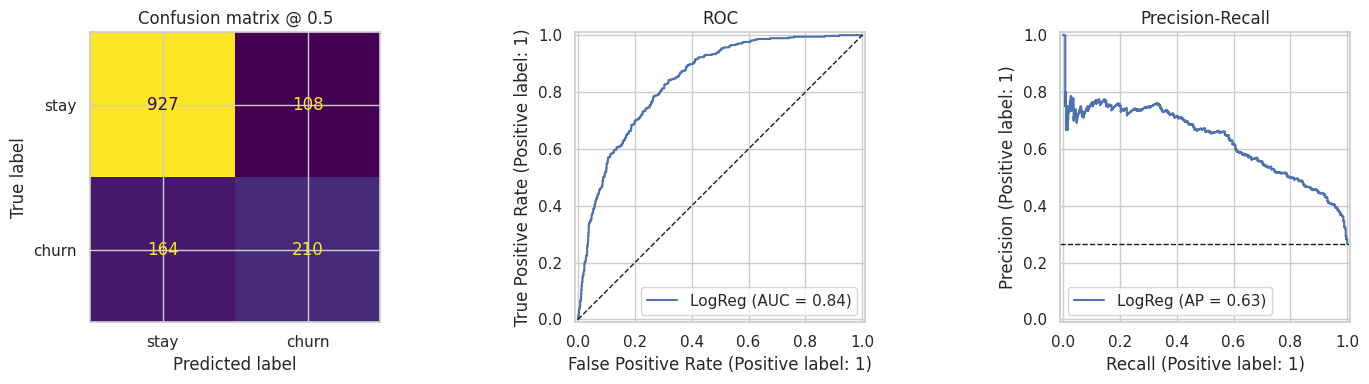

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay(confusion_matrix(yt, pred05), display_labels=["stay","churn"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix @ 0.5")
RocCurveDisplay.from_predictions(yt, p_test, ax=axes[1], name=FINAL_NAME); axes[1].plot([0,1],[0,1],"k--",lw=1); axes[1].set_title("ROC")
PrecisionRecallDisplay.from_predictions(yt, p_test, ax=axes[2], name=FINAL_NAME); axes[2].axhline(yt.mean(), color="k", ls="--", lw=1); axes[2].set_title("Precision-Recall")
plt.tight_layout(); plt.show()

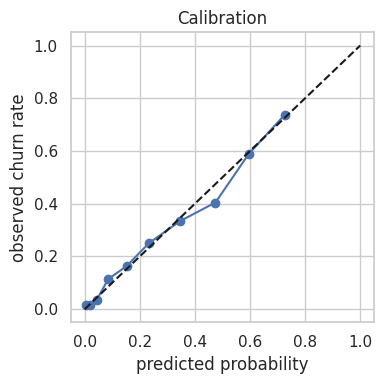

In [10]:
fp, mp = calibration_curve(yt, p_test, n_bins=10, strategy="quantile")
plt.figure(figsize=(4,4)); plt.plot(mp, fp, "o-"); plt.plot([0,1],[0,1],"k--")
plt.xlabel("predicted probability"); plt.ylabel("observed churn rate"); plt.title("Calibration"); plt.tight_layout(); plt.show()

## 15. Threshold Analysis
Choose an operating threshold using out-of-fold training predictions and expected net benefit.

In [11]:
def net_benefit_per_1000(y_true, flagged, monthly, save_rate=SAVE_RATE, offer_cost=OFFER_COST):
    y_true, flagged, monthly = np.asarray(y_true), np.asarray(flagged).astype(bool), np.asarray(monthly)
    gain = (y_true[flagged] * save_rate * VALUE_MONTHS * monthly[flagged]).sum() - offer_cost * flagged.sum()
    return 1000 * gain / len(y_true)

oof = cross_val_predict(clone(final_model), X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
grid = np.round(np.arange(0.02, 0.91, 0.01), 2)
mc_train = X_train["MonthlyCharges"].values
curve = pd.DataFrame({
    "threshold": grid,
    "precision": [precision_score(y_train, oof >= t, zero_division=0) for t in grid],
    "recall":    [recall_score(y_train, oof >= t) for t in grid],
    "f1":        [f1_score(y_train, oof >= t) for t in grid],
    "benefit_per_1000": [net_benefit_per_1000(y_train, oof >= t, mc_train) for t in grid]})
THRESHOLD = float(curve.loc[curve.benefit_per_1000.idxmax(), "threshold"])
print("Chosen threshold (max expected net benefit):", THRESHOLD)
display(curve[curve.threshold.isin([0.1,0.2,0.3,THRESHOLD,0.4,0.5,0.6])].drop_duplicates("threshold").round(3))

Chosen threshold (max expected net benefit): 0.07


,threshold,precision,recall,f1,benefit_per_1000
5,0.07,0.376,0.963,0.540,55651.157
8,0.10,0.400,0.938,0.561,55178.165
18,0.20,0.474,0.858,0.611,53368.491
28,0.30,0.541,0.769,0.635,49889.872
38,0.40,0.593,0.662,0.626,44526.436
48,0.50,0.655,0.546,0.596,38079.148
58,0.60,0.715,0.399,0.512,28487.039


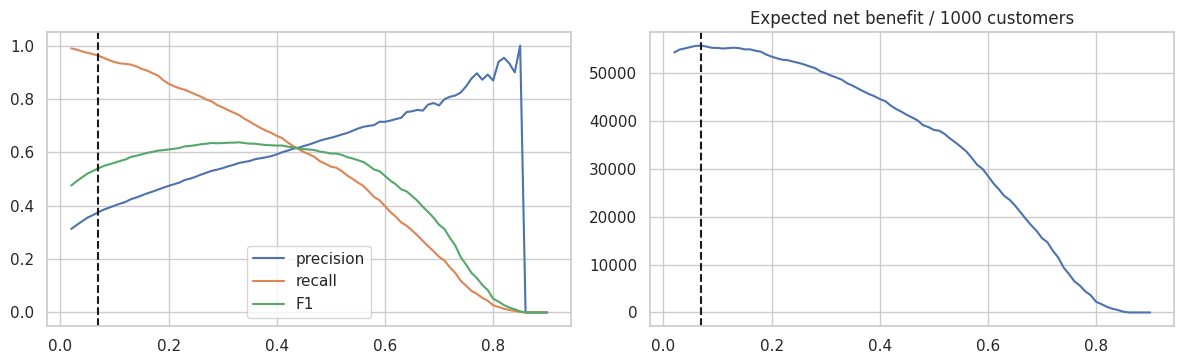

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(curve.threshold, curve.precision, label="precision"); axes[0].plot(curve.threshold, curve.recall, label="recall")
axes[0].plot(curve.threshold, curve.f1, label="F1"); axes[0].axvline(THRESHOLD, color="k", ls="--"); axes[0].legend()
axes[1].plot(curve.threshold, curve.benefit_per_1000); axes[1].axvline(THRESHOLD, color="k", ls="--"); axes[1].set_title("Expected net benefit / 1000 customers")
plt.tight_layout(); plt.show()

In [13]:
pred = (p_test >= THRESHOLD).astype(int)
print("At the chosen threshold, on the TEST set:")
print("  Precision:", round(precision_score(yt, pred), 3))
print("  Recall   :", round(recall_score(yt, pred), 3))
print("  F1       :", round(f1_score(yt, pred), 3))
print("  Share of customers flagged:", round(pred.mean(), 3))

At the chosen threshold, on the TEST set:
  Precision: 0.379
  Recall   : 0.973
  F1       : 0.546
  Share of customers flagged: 0.681
